# 03 — Regresión logística y KNN

**Objetivo.** Comparar regresión logística y K vecinos más cercanos (KNN) para predecir churn, con AUC-ROC como métrica principal. La selección de hiperparámetros se hace dentro del desarrollo mediante validación cruzada repetida; el conjunto de validación final queda intacto hasta la comparación final.

> Este notebook no produce todavía el submission de Kaggle. Primero documenta una elección de modelo reproducible y estadísticamente defendible.

In [22]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import importlib
import sys

PROYECTO_IMPORTS = Path.cwd().resolve()
if PROYECTO_IMPORTS.name == 'notebooks':
    PROYECTO_IMPORTS = PROYECTO_IMPORTS.parent
if str(PROYECTO_IMPORTS) not in sys.path:
    sys.path.insert(0, str(PROYECTO_IMPORTS))

from src import transformaciones as tr

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (auc, brier_score_loss, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.calibration import calibration_curve

RANDOM_STATE = 2026
RUN_ID = datetime.now(ZoneInfo('America/Bogota')).strftime('%Y%m%d_%H%M%S')
RAIZ = Path.cwd().resolve()
if RAIZ.name == 'notebooks':
    RAIZ = RAIZ.parent
PROCESSED = RAIZ / 'data' / 'processed'
OUTPUTS = RAIZ / 'outputs'
OUTPUTS.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook', palette='deep')
plt.rcParams['figure.dpi'] = 110

## 1. Datos y diseño de validación

Se excluyen identificador y fechas originales. Las fechas ya fueron convertidas en edad y antigüedad contractual en el notebook 01. La validación final estratificada (20%) no participa en la selección de `C` ni de `k`.

In [23]:
# Recarga el archivo src/transformaciones.py cada vez que se ejecuta esta celda.
importlib.reload(tr)
NOMBRE_CONFIGURACION = tr.CONFIGURACION_ACTIVA
configuracion = tr.obtener_configuracion(NOMBRE_CONFIGURACION)

train_original = pd.read_csv(PROCESSED / 'train_preparado.csv')
train = tr.aplicar_transformaciones(train_original, configuracion)

OBJETIVO = 'resultado'
NUMERICAS, SPLINES, CATEGORICAS = tr.obtener_grupos(configuracion)
PREDICTORES = NUMERICAS + SPLINES + CATEGORICAS

X = train[PREDICTORES].copy()
y = train[OBJETIVO].copy()
X_dev, X_val, y_dev, y_val = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

diseno = pd.DataFrame({
    'muestra': ['desarrollo', 'validación final'],
    'clientes': [len(X_dev), len(X_val)],
    'tasa_churn': [y_dev.mean(), y_val.mean()],
    'configuración': [NOMBRE_CONFIGURACION, NOMBRE_CONFIGURACION]
})
display(diseno.style.format({'tasa_churn': '{:.1%}'}))


,muestra,clientes,tasa_churn,configuración
0,desarrollo,6594,16.5%,spline_mora_3_nudos
1,validación final,1649,16.5%,spline_mora_3_nudos


## 2. Preprocesamiento dentro de pipelines

La imputación, codificación y estandarización se ajustan dentro de cada partición de validación cruzada. Esto evita que información de validación influya en los parámetros de transformación. El escalamiento es indispensable para KNN y también permite expresar los odds ratios de las variables numéricas por una desviación estándar.

In [24]:
# El detalle de las variables transformadas vive en src/transformaciones.py.
# Este objeto entra en cada Pipeline y se ajusta solo con el entrenamiento de cada fold.
preprocesador = tr.crear_preprocesador(configuracion)

cv_repetida = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
N_EVALUACIONES_CV = 15


## 3. Selección de hiperparámetros mediante AUC-ROC

- **Logística:** `C` controla la regularización L2. Valores pequeños regularizan más.
- **KNN:** se prueban valores impares de `k` para reducir empates. El AUC promedio se acompaña de su intervalo aproximado de 95% sobre las 15 particiones repetidas.

Los resultados de esta sección sirven para elegir configuraciones; no son el desempeño final reportable.

In [25]:
pipeline_logistica = Pipeline([
    ('preprocesar', preprocesador),
    ('modelo', LogisticRegression(max_iter=3000, solver='liblinear', random_state=RANDOM_STATE))
])
pipeline_knn = Pipeline([
    ('preprocesar', preprocesador),
    ('modelo', KNeighborsClassifier())
])

busqueda_logistica = GridSearchCV(
    pipeline_logistica,
    param_grid={'modelo__C': [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30]},
    scoring='roc_auc', cv=cv_repetida, n_jobs=-1, refit=True, return_train_score=False
)
busqueda_knn = GridSearchCV(
    pipeline_knn,
    param_grid={'modelo__n_neighbors': list(range(3, 62, 2)), 'modelo__weights': ['uniform', 'distance']},
    scoring='roc_auc', cv=cv_repetida, n_jobs=-1, refit=True, return_train_score=False
)

busqueda_logistica.fit(X_dev, y_dev)
busqueda_knn.fit(X_dev, y_dev)

def resultados_cv(busqueda, parametros):
    tabla = pd.DataFrame(busqueda.cv_results_)
    columnas = parametros + ['mean_test_score', 'std_test_score', 'rank_test_score']
    tabla = tabla[columnas].rename(columns={'mean_test_score': 'auc_media', 'std_test_score': 'desv_auc', 'rank_test_score': 'rango'})
    tabla['ic95_inf'] = tabla.auc_media - 1.96 * tabla.desv_auc / np.sqrt(N_EVALUACIONES_CV)
    tabla['ic95_sup'] = tabla.auc_media + 1.96 * tabla.desv_auc / np.sqrt(N_EVALUACIONES_CV)
    return tabla.sort_values(['rango', 'auc_media'], ascending=[True, False]).reset_index(drop=True)

cv_logistica = resultados_cv(busqueda_logistica, ['param_modelo__C'])
cv_knn = resultados_cv(busqueda_knn, ['param_modelo__n_neighbors', 'param_modelo__weights'])
display(cv_logistica.head(8).style.format({'auc_media': '{:.4f}', 'desv_auc': '{:.4f}', 'ic95_inf': '{:.4f}', 'ic95_sup': '{:.4f}'}))
display(cv_knn.head(10).style.format({'auc_media': '{:.4f}', 'desv_auc': '{:.4f}', 'ic95_inf': '{:.4f}', 'ic95_sup': '{:.4f}'}))

,param_modelo__C,auc_media,desv_auc,rango,ic95_inf,ic95_sup
0,30.000000,0.7877,0.0128,1,0.7812,0.7942
1,10.000000,0.7877,0.0128,2,0.7812,0.7942
2,3.000000,0.7876,0.0128,3,0.7811,0.7940
3,1.000000,0.7873,0.0126,4,0.7809,0.7937
4,0.300000,0.7861,0.0123,5,0.7799,0.7924
5,0.100000,0.7827,0.0122,6,0.7765,0.7888
6,0.030000,0.7732,0.0128,7,0.7667,0.7797
7,0.010000,0.7579,0.0138,8,0.7509,0.7649


,param_modelo__n_neighbors,param_modelo__weights,auc_media,desv_auc,rango,ic95_inf,ic95_sup
0,61,distance,0.8053,0.0130,1,0.7987,0.8119
1,59,distance,0.8053,0.0130,2,0.7987,0.8119
2,57,distance,0.8049,0.0128,3,0.7985,0.8114
3,51,distance,0.8048,0.0126,4,0.7985,0.8112
4,53,distance,0.8048,0.0123,5,0.7985,0.8110
5,55,distance,0.8047,0.0128,6,0.7982,0.8111
6,49,distance,0.8042,0.0126,7,0.7979,0.8106
7,47,distance,0.8040,0.0129,8,0.7975,0.8105
8,45,distance,0.8038,0.0129,9,0.7972,0.8103
9,43,distance,0.8032,0.0133,10,0.7965,0.8100


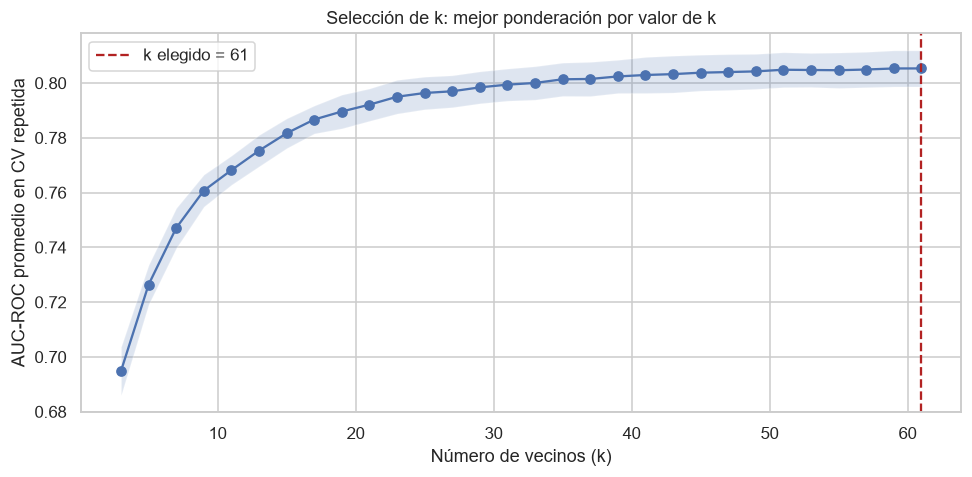

In [26]:
mejor_knn_por_k = (cv_knn.sort_values(['param_modelo__n_neighbors', 'auc_media'], ascending=[True, False])
                    .groupby('param_modelo__n_neighbors', as_index=False).first())
plt.figure(figsize=(9, 4.5))
plt.plot(mejor_knn_por_k.param_modelo__n_neighbors, mejor_knn_por_k.auc_media, marker='o')
plt.fill_between(mejor_knn_por_k.param_modelo__n_neighbors, mejor_knn_por_k.ic95_inf, mejor_knn_por_k.ic95_sup, alpha=.18)
plt.axvline(busqueda_knn.best_params_['modelo__n_neighbors'], color='firebrick', linestyle='--', label=f"k elegido = {busqueda_knn.best_params_['modelo__n_neighbors']}")
plt.xlabel('Número de vecinos (k)')
plt.ylabel('AUC-ROC promedio en CV repetida')
plt.title('Selección de k: mejor ponderación por valor de k')
plt.legend()
plt.tight_layout(); plt.show()

## 4. Comparación final en validación intacta

Cada modelo seleccionado se evalúa una sola vez en la muestra apartada. Además de AUC, se reporta Brier score para la calidad de las probabilidades (menor es mejor) y un intervalo bootstrap pareado para la diferencia de AUC entre logística y KNN.

In [27]:
modelo_logistica = busqueda_logistica.best_estimator_
modelo_knn = busqueda_knn.best_estimator_

prob_logistica = modelo_logistica.predict_proba(X_val)[:, 1]
prob_knn = modelo_knn.predict_proba(X_val)[:, 1]
auc_logistica = roc_auc_score(y_val, prob_logistica)
auc_knn = roc_auc_score(y_val, prob_knn)

comparacion_final = pd.DataFrame({
    'modelo': ['Regresión logística', 'KNN'],
    'mejor_configuracion': [str(busqueda_logistica.best_params_), str(busqueda_knn.best_params_)],
    'auc_validacion': [auc_logistica, auc_knn],
    'brier_validacion': [brier_score_loss(y_val, prob_logistica), brier_score_loss(y_val, prob_knn)]
})
display(comparacion_final.style.format({'auc_validacion': '{:.4f}', 'brier_validacion': '{:.4f}'}))

rng = np.random.default_rng(RANDOM_STATE)
diferencias = []
y_val_np = y_val.to_numpy()
for _ in range(2000):
    idx = rng.integers(0, len(y_val_np), len(y_val_np))
    if len(np.unique(y_val_np[idx])) == 2:
        diferencias.append(roc_auc_score(y_val_np[idx], prob_logistica[idx]) - roc_auc_score(y_val_np[idx], prob_knn[idx]))
ic_diferencia = np.quantile(diferencias, [.025, .975])
display(pd.DataFrame({
    'comparación': ['AUC logística − AUC KNN'],
    'diferencia_observada': [auc_logistica - auc_knn],
    'IC95_bootstrap_inf': [ic_diferencia[0]],
    'IC95_bootstrap_sup': [ic_diferencia[1]]
}).style.format({'diferencia_observada': '{:.4f}', 'IC95_bootstrap_inf': '{:.4f}', 'IC95_bootstrap_sup': '{:.4f}'}))

,modelo,mejor_configuracion,auc_validacion,brier_validacion
0,Regresión logística,{'modelo__C': 30},0.7947,0.1091
1,KNN,"{'modelo__n_neighbors': 61, 'modelo__weights': 'distance'}",0.8215,0.1095


,comparación,diferencia_observada,IC95_bootstrap_inf,IC95_bootstrap_sup
0,AUC logística − AUC KNN,-0.0268,-0.0497,-0.0021


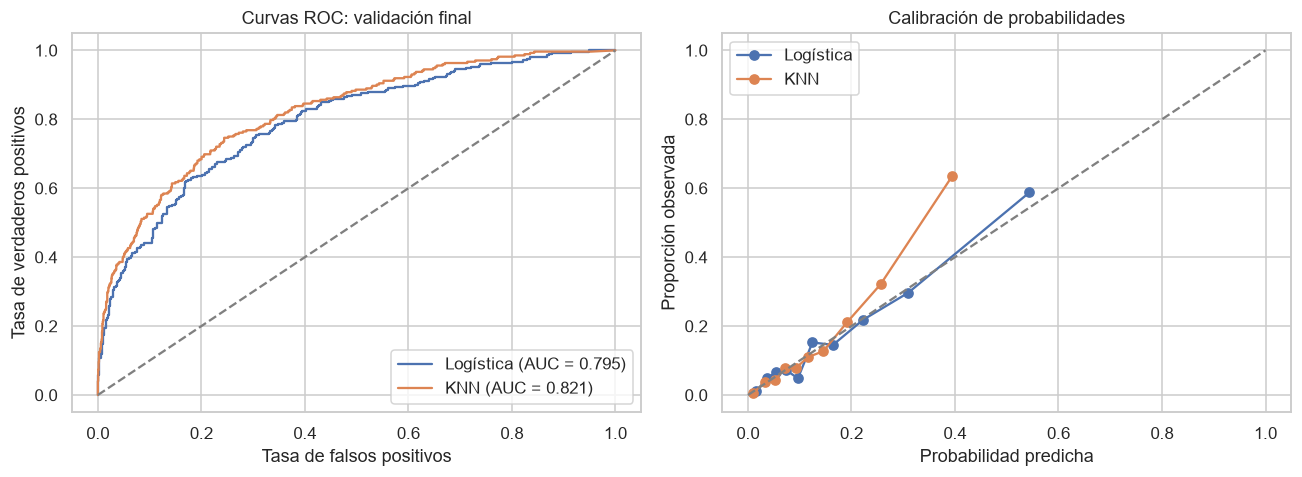

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for nombre, prob, color in [('Logística', prob_logistica, sns.color_palette()[0]), ('KNN', prob_knn, sns.color_palette()[1])]:
    fpr, tpr, _ = roc_curve(y_val, prob)
    axes[0].plot(fpr, tpr, label=f'{nombre} (AUC = {auc(fpr, tpr):.3f})', color=color)
    fraccion, media_predicha = calibration_curve(y_val, prob, n_bins=10, strategy='quantile')
    axes[1].plot(media_predicha, fraccion, marker='o', label=nombre, color=color)
axes[0].plot([0, 1], [0, 1], '--', color='gray')
axes[0].set(title='Curvas ROC: validación final', xlabel='Tasa de falsos positivos', ylabel='Tasa de verdaderos positivos')
axes[0].legend(loc='lower right')
axes[1].plot([0, 1], [0, 1], '--', color='gray')
axes[1].set(title='Calibración de probabilidades', xlabel='Probabilidad predicha', ylabel='Proporción observada')
axes[1].legend()
plt.tight_layout(); plt.show()

## 5. Odds ratios de la regresión logística

La logística se reestima sobre desarrollo con la configuración elegida. Para las variables numéricas, el odds ratio representa un aumento de **una desviación estándar**, pues fueron estandarizadas. Para las categorías, representa el cambio frente a la categoría de referencia. Los intervalos de 95% se obtienen por bootstrap en desarrollo; expresan incertidumbre muestral del modelo, no causalidad.

In [29]:
prepro_odds = clone(preprocesador).fit(X_dev, y_dev)
X_dev_transformado = prepro_odds.transform(X_dev)
modelo_base_odds = clone(modelo_logistica.named_steps['modelo']).fit(X_dev_transformado, y_dev)
nombres = prepro_odds.get_feature_names_out()

N_BOOTSTRAP = 300
coeficientes_bootstrap = np.empty((N_BOOTSTRAP, len(nombres)))
indices_por_clase = [np.flatnonzero(y_dev.to_numpy() == clase) for clase in sorted(y_dev.unique())]
for b in range(N_BOOTSTRAP):
    idx = np.concatenate([rng.choice(indices, size=len(indices), replace=True) for indices in indices_por_clase])
    modelo_b = clone(modelo_base_odds).fit(X_dev_transformado[idx], y_dev.to_numpy()[idx])
    coeficientes_bootstrap[b] = modelo_b.coef_.ravel()

odds = pd.DataFrame({
    'variable': nombres,
    'coeficiente_log_odds': modelo_base_odds.coef_.ravel(),
    'odds_ratio': np.exp(modelo_base_odds.coef_.ravel()),
    'or_ic95_inf': np.exp(np.quantile(coeficientes_bootstrap, .025, axis=0)),
    'or_ic95_sup': np.exp(np.quantile(coeficientes_bootstrap, .975, axis=0)),
})
odds['interpretacion'] = np.where(odds.variable.str.startswith('num__'), 'Por +1 desviación estándar', 'Frente a la categoría de referencia')
odds['evidencia_bootstrap'] = np.where((odds.or_ic95_inf > 1) | (odds.or_ic95_sup < 1), 'IC95% no contiene 1', 'IC95% contiene 1')
odds['distancia_de_1'] = np.abs(odds.coeficiente_log_odds)
odds = odds.sort_values('distancia_de_1', ascending=False).drop(columns='distancia_de_1')
display(odds.style.format({'coeficiente_log_odds': '{:.3f}', 'odds_ratio': '{:.3f}', 'or_ic95_inf': '{:.3f}', 'or_ic95_sup': '{:.3f}'}))

,variable,coeficiente_log_odds,odds_ratio,or_ic95_inf,or_ic95_sup,interpretacion,evidencia_bootstrap
9,categoricas__antiguedad_contrato_invalida_1,-1.937,0.144,0.055,1.000,Frente a la categoría de referencia,IC95% contiene 1
6,categoricas__tipo_cliente_3,1.663,5.273,4.385,6.589,Frente a la categoría de referencia,IC95% no contiene 1
13,splines__mora_sp_3,-1.606,0.201,0.096,0.329,Frente a la categoría de referencia,IC95% no contiene 1
14,splines__mora_sp_4,1.055,2.872,2.113,4.857,Frente a la categoría de referencia,IC95% no contiene 1
12,splines__mora_sp_2,0.985,2.679,2.123,3.659,Frente a la categoría de referencia,IC95% no contiene 1
1,numericas__facturacion,0.809,2.247,2.085,2.450,Frente a la categoría de referencia,IC95% no contiene 1
3,numericas__edad_anios,0.757,2.131,1.934,2.323,Frente a la categoría de referencia,IC95% no contiene 1
11,splines__mora_sp_1,-0.534,0.587,0.505,0.655,Frente a la categoría de referencia,IC95% no contiene 1
4,numericas__antiguedad_contrato_meses,0.442,1.556,1.389,1.768,Frente a la categoría de referencia,IC95% no contiene 1
5,categoricas__tipo_cliente_2,0.393,1.481,1.306,1.733,Frente a la categoría de referencia,IC95% no contiene 1


## 6. Registro de resultados

Se guardan las tablas de selección y odds ratios para apoyar el informe CRISP-DM. La decisión final debe considerar AUC, calibración, estabilidad de CV e interpretabilidad; si el intervalo de diferencia de AUC contiene cero, no hay evidencia clara de superioridad entre los dos modelos en esta partición.

In [30]:
cv_logistica.assign(modelo='Regresión logística').to_csv(OUTPUTS / f'cv_logistica_{NOMBRE_CONFIGURACION}.csv', index=False)
cv_knn.assign(modelo='KNN').to_csv(OUTPUTS / f'cv_knn_{NOMBRE_CONFIGURACION}.csv', index=False)
comparacion_final.to_csv(OUTPUTS / f'comparacion_validacion_{NOMBRE_CONFIGURACION}.csv', index=False)
odds.to_csv(OUTPUTS / f'odds_ratios_logistica_{NOMBRE_CONFIGURACION}.csv', index=False)

display(pd.DataFrame({
    'archivo': [f'cv_logistica_{NOMBRE_CONFIGURACION}.csv', f'cv_knn_{NOMBRE_CONFIGURACION}.csv', f'comparacion_validacion_{NOMBRE_CONFIGURACION}.csv', f'odds_ratios_logistica_{NOMBRE_CONFIGURACION}.csv'],
    'contenido': ['Resultados de C', 'Resultados de k y ponderación', 'Desempeño final intacto', 'Odds ratios con IC bootstrap']
}))

,archivo,contenido
0,cv_logistica_spline_mora_3_nudos.csv,Resultados de C
1,cv_knn_spline_mora_3_nudos.csv,Resultados de k y ponderación
2,comparacion_validacion_spline_mora_3_nudos.csv,Desempeño final intacto
3,odds_ratios_logistica_spline_mora_3_nudos.csv,Odds ratios con IC bootstrap


## 7. Predicciones para Kaggle y trazabilidad

Cada configuración ganadora se reentrena con todos los registros de entrenamiento y genera probabilidades para `testelco`. Se conservan los dos candidatos y un archivo final. Los CSV contienen únicamente `id` y `resultado`.

Si el intervalo bootstrap de la diferencia de AUC contiene cero, la elección final debe justificarse también por calibración, estabilidad e interpretabilidad.

In [31]:
PREDICCIONES = OUTPUTS / 'predicciones' / NOMBRE_CONFIGURACION
PREDICCIONES.mkdir(parents=True, exist_ok=True)
test_original = pd.read_csv(PROCESSED / 'test_preparado.csv')
test = tr.aplicar_transformaciones(test_original, configuracion)
X_test = test[PREDICTORES].copy()
assert list(X_test.columns) == list(X.columns)

# Reentrenamiento con todo train: la validación ya cumplió su función de comparación.
logistica_final = clone(pipeline_logistica).set_params(**busqueda_logistica.best_params_).fit(X, y)
knn_final = clone(pipeline_knn).set_params(**busqueda_knn.best_params_).fit(X, y)

def etiqueta_numero(valor):
    return str(valor).replace('.', 'p')

def crear_submission(modelo, nombre):
    submission = pd.DataFrame({'id': test['id'], 'resultado': modelo.predict_proba(X_test)[:, 1]})
    assert submission.id.equals(test.id)
    assert submission.resultado.between(0, 1).all()
    submission.to_csv(PREDICCIONES / nombre, index=False)
    return submission

nombre_logistica = f"submission_logistica_C_{etiqueta_numero(busqueda_logistica.best_params_['modelo__C'])}.csv"
nombre_knn = f"submission_knn_k_{busqueda_knn.best_params_['modelo__n_neighbors']}_pesos_{busqueda_knn.best_params_['modelo__weights']}.csv"
submission_logistica = crear_submission(logistica_final, nombre_logistica)
submission_knn = crear_submission(knn_final, nombre_knn)

modelo_elegido = comparacion_final.loc[comparacion_final.auc_validacion.idxmax(), 'modelo']
submission_final = submission_logistica if modelo_elegido == 'Regresión logística' else submission_knn
nombre_final = 'submission_final_logistica.csv' if modelo_elegido == 'Regresión logística' else 'submission_final_knn.csv'
submission_final.to_csv(PREDICCIONES / nombre_final, index=False)

trazabilidad = pd.DataFrame({
    'archivo': [nombre_logistica, nombre_knn, nombre_final],
    'modelo': ['Regresión logística', 'KNN', modelo_elegido],
    'parametros': [str(busqueda_logistica.best_params_), str(busqueda_knn.best_params_), 'seleccionado por AUC de validación'],
    'auc_validacion': [auc_logistica, auc_knn, max(auc_logistica, auc_knn)],
    'filas_test': [len(test), len(test), len(test)]
})
trazabilidad.to_csv(PREDICCIONES / 'trazabilidad_submissions.csv', index=False)
display(trazabilidad.style.format({'auc_validacion': '{:.4f}'}))

,archivo,modelo,parametros,auc_validacion,filas_test
0,submission_logistica_C_30.csv,Regresión logística,{'modelo__C': 30},0.7947,2000
1,submission_knn_k_61_pesos_distance.csv,KNN,"{'modelo__n_neighbors': 61, 'modelo__weights': 'distance'}",0.8215,2000
2,submission_final_knn.csv,KNN,seleccionado por AUC de validación,0.8215,2000


## 8. Registro obligatorio del experimento

Esta celda escribe o actualiza `outputs/experimentos/registro_experimentos.csv`. Debe ejecutarse después de que estén calculadas las métricas de ambos modelos.

In [32]:
# Esta es la última celda obligatoria de cada ejecución del notebook 03.
# Puedes editar estos dos campos antes de ejecutarla.
COMENTARIO_EXPERIMENTO = "Primera ejecución de esta configuración"
AUC_KAGGLE_PUBLICO = pd.NA  # Reemplazar después de subir el submission correspondiente.

CARPETA_EXPERIMENTOS = OUTPUTS / 'experimentos'
CARPETA_EXPERIMENTOS.mkdir(parents=True, exist_ok=True)
ARCHIVO_REGISTRO = CARPETA_EXPERIMENTOS / 'registro_experimentos.csv'

metricas_finales = comparacion_final.set_index('modelo')
registros_nuevos = pd.DataFrame([
    {
        'run_id': RUN_ID,
        'fecha_hora_bogota': datetime.now(ZoneInfo('America/Bogota')).isoformat(timespec='seconds'),
        'configuracion': NOMBRE_CONFIGURACION,
        'transformaciones': str(configuracion),
        'modelo': 'Regresión logística',
        'parametros': str(busqueda_logistica.best_params_),
        'auc_cv_repetida': busqueda_logistica.best_score_,
        'auc_validacion': metricas_finales.loc['Regresión logística', 'auc_validacion'],
        'brier_validacion': metricas_finales.loc['Regresión logística', 'brier_validacion'],
        'auc_kaggle_publico': AUC_KAGGLE_PUBLICO,
        'clientes_entrenamiento': len(X_dev),
        'clientes_validacion': len(X_val),
        'random_state': RANDOM_STATE,
        'comentario': COMENTARIO_EXPERIMENTO,
    },
    {
        'run_id': RUN_ID,
        'fecha_hora_bogota': datetime.now(ZoneInfo('America/Bogota')).isoformat(timespec='seconds'),
        'configuracion': NOMBRE_CONFIGURACION,
        'transformaciones': str(configuracion),
        'modelo': 'KNN',
        'parametros': str(busqueda_knn.best_params_),
        'auc_cv_repetida': busqueda_knn.best_score_,
        'auc_validacion': metricas_finales.loc['KNN', 'auc_validacion'],
        'brier_validacion': metricas_finales.loc['KNN', 'brier_validacion'],
        'auc_kaggle_publico': AUC_KAGGLE_PUBLICO,
        'clientes_entrenamiento': len(X_dev),
        'clientes_validacion': len(X_val),
        'random_state': RANDOM_STATE,
        'comentario': COMENTARIO_EXPERIMENTO,
    },
])

if ARCHIVO_REGISTRO.exists():
    registro = pd.read_csv(ARCHIVO_REGISTRO)
    registro = pd.concat([registro, registros_nuevos], ignore_index=True)
    # Reejecutar esta celda actualiza el mismo run, en vez de duplicarlo.
    registro = registro.drop_duplicates(subset=['run_id', 'modelo'], keep='last')
else:
    registro = registros_nuevos

registro.to_csv(ARCHIVO_REGISTRO, index=False)
display(registro.tail(10).style.format({
    'auc_cv_repetida': '{:.4f}',
    'auc_validacion': '{:.4f}',
    'brier_validacion': '{:.4f}',
    'auc_kaggle_publico': '{:.4f}',
}))


,run_id,fecha_hora_bogota,configuracion,transformaciones,modelo,parametros,auc_cv_repetida,auc_validacion,brier_validacion,auc_kaggle_publico,clientes_entrenamiento,clientes_validacion,random_state,comentario
0,historico_baseline_20261106,2026-11-06T22:48:58-05:00,baseline,sin transformaciones avanzadas,Regresión logística,{'modelo__C': 1},0.7751,0.7791,0.1108,nan,6594,1649,2026,Referencia histórica recuperada de outputs
1,historico_baseline_20261106,2026-11-06T22:48:58-05:00,baseline,sin transformaciones avanzadas,KNN,"{'modelo__n_neighbors': 57, 'modelo__weights': 'distance'}",0.7878,0.8026,0.1127,0.7943,6594,1649,2026,Submission baseline enviado a Kaggle
2,transformaciones_20261107,2026-11-07T17:00:22-05:00,log_mora_minutos_facturacion,log1p mora y minutos; separación de facturación negativa,Regresión logística,{'modelo__C': 3},0.7804,0.7836,0.1109,nan,6594,1649,2026,Mejora ligera en logística
3,transformaciones_20261107,2026-11-07T17:00:22-05:00,log_mora_minutos_facturacion,log1p mora y minutos; separación de facturación negativa,KNN,"{'modelo__n_neighbors': 61, 'modelo__weights': 'distance'}",0.7680,0.7853,0.1149,0.7844,6594,1649,2026,Submission con caída frente al baseline
4,20261107_172649,2026-11-07T17:27:25-05:00,spline_mora,"{'log_mora': False, 'log_minutos': False, 'ajustar_facturacion': False, 'splines': ['mora']}",Regresión logística,{'modelo__C': 1},0.8107,0.8164,0.1031,nan,6594,1649,2026,Primera ejecución de esta configuración
5,20261107_172649,2026-11-07T17:27:25-05:00,spline_mora,"{'log_mora': False, 'log_minutos': False, 'ajustar_facturacion': False, 'splines': ['mora']}",KNN,"{'modelo__n_neighbors': 59, 'modelo__weights': 'distance'}",0.8054,0.8133,0.1094,nan,6594,1649,2026,Primera ejecución de esta configuración
6,20261107_174931,2026-11-07T17:50:11-05:00,spline_mora_3_nudos,"{'log_mora': False, 'log_minutos': False, 'ajustar_facturacion': False, 'splines': ['mora'], 'n_knots': 3}",Regresión logística,{'modelo__C': 30},0.7877,0.7947,0.1091,,6594,1649,2026,Primera ejecución de esta configuración
7,20261107_174931,2026-11-07T17:50:11-05:00,spline_mora_3_nudos,"{'log_mora': False, 'log_minutos': False, 'ajustar_facturacion': False, 'splines': ['mora'], 'n_knots': 3}",KNN,"{'modelo__n_neighbors': 61, 'modelo__weights': 'distance'}",0.8053,0.8215,0.1095,,6594,1649,2026,Primera ejecución de esta configuración
